In [1]:

# text classification with linear models
# Dataset: NLTK Movie Reviews

# STEP 1: IMPORT LIBRARIES

import nltk
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import movie_reviews

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score,
    f1_score
)

# Download the dataset
nltk.download('movie_reviews')
nltk.download('punkt', quiet=True)


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


True

In [2]:


# STEP 2: LOAD THE DATASET

documents = []
labels = []

for fileid in movie_reviews.fileids():

    # Get the review text
    text = movie_reviews.raw(fileid)

    # Get the category: pos or neg
    label = movie_reviews.categories(fileid)[0]

    documents.append(text)
    labels.append(label)

documents = np.array(documents)
labels = np.array(labels)

print("Dataset loaded successfully!")
print("Total documents:", len(documents))
print("Positive reviews:", sum(labels == "pos"))
print("Negative reviews:", sum(labels == "neg"))



Dataset loaded successfully!
Total documents: 2000
Positive reviews: 1000
Negative reviews: 1000


In [3]:

# STEP 3: PREPROCESS THE TEXT

def preprocess(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


clean_documents = [preprocess(doc) for doc in documents]


In [4]:


# STEP 4: SPLIT DATA INTO TRAINING, DEVELOPMENT AND TEST SETS

# First: 70% training, 30% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    clean_documents,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second: Divide remaining data into 15% development and 15% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)

print("\nDATASET SPLIT")
print("Training documents:", len(X_train))
print("Development documents:", len(X_dev))
print("Test documents:", len(X_test))




DATASET SPLIT
Training documents: 1400
Development documents: 300
Test documents: 300


In [5]:

from itertools import product

class_names = ['neg', 'pos']
C_values = [0.01, 0.1, 1, 10, 100]

feature_grid = {
    'ngram_range': [(1, 1), (1, 2), (1, 3)],
    'min_df': [2, 5],
    'max_features': [5000, 10000, None],
}

best_config, best_C, best_dev_f1 = None, None, -1
tuning_log = []

for ngram, min_df, max_feat in product(
        feature_grid['ngram_range'],
        feature_grid['min_df'],
        feature_grid['max_features']):

    vec = TfidfVectorizer(ngram_range=ngram, min_df=min_df,
                          max_features=max_feat, sublinear_tf=True)
    Xtr = vec.fit_transform(X_train)   # fit on training data only
    Xdv = vec.transform(X_dev)

    for C in C_values:
        m = LogisticRegression(C=C, max_iter=1000, random_state=42)
        m.fit(Xtr, y_train)
        f1 = f1_score(y_dev, m.predict(Xdv), labels=class_names, average='macro')
        tuning_log.append((ngram, min_df, max_feat, C, round(f1, 4)))

        if f1 > best_dev_f1:
            best_dev_f1, best_C = f1, C
            best_config = dict(ngram_range=ngram, min_df=min_df, max_features=max_feat)

print("Best features:", best_config, "| Best C:", best_C,
      "| Dev macro F1:", round(best_dev_f1, 4))

# Refit the winning vectorizer, then continue with your Step 6 onward
vectorizer = TfidfVectorizer(sublinear_tf=True, **best_config)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)
X_test_tfidf = vectorizer.transform(X_test)


Best features: {'ngram_range': (1, 2), 'min_df': 5, 'max_features': 10000} | Best C: 10 | Dev macro F1: 0.8833


In [6]:
import pandas as pd

log = pd.DataFrame(tuning_log,
                   columns=['ngram_range', 'min_df', 'max_features', 'C', 'dev_macro_F1'])

# 1. The 10 best configurations
print(log.sort_values('dev_macro_F1', ascending=False).head(10).to_string())

# 2. Best score for each feature limit (is 5,000 worse than 10,000?)
print(log.groupby('max_features', dropna=False)['dev_macro_F1'].max())

# 3. Best score for each C (does stronger regularisation help?)
print(log.groupby('C')['dev_macro_F1'].max())

   ngram_range  min_df  max_features      C  dev_macro_F1
53      (1, 2)       5       10000.0   10.0        0.8833
38      (1, 2)       2       10000.0   10.0        0.8800
83      (1, 3)       5       10000.0   10.0        0.8800
54      (1, 2)       5       10000.0  100.0        0.8766
39      (1, 2)       2       10000.0  100.0        0.8766
84      (1, 3)       5       10000.0  100.0        0.8766
68      (1, 3)       2       10000.0   10.0        0.8733
69      (1, 3)       2       10000.0  100.0        0.8733
3       (1, 1)       2        5000.0   10.0        0.8700
14      (1, 1)       2           NaN  100.0        0.8700
max_features
5000.0     0.8700
10000.0    0.8833
NaN        0.8700
Name: dev_macro_F1, dtype: float64
C
0.01      0.8399
0.10      0.8399
1.00      0.8567
10.00     0.8833
100.00    0.8766
Name: dev_macro_F1, dtype: float64


In [7]:

# STEP 6: DATASET STATISTICS

all_words = [len(doc.split()) for doc in clean_documents]

print("\nDATASET STATISTICS")
print("---------------------------")
print("Total documents:", len(documents))
print("Average document length:", round(np.mean(all_words), 2))
print("Training documents:", len(X_train))
print("Development documents:", len(X_dev))
print("Test documents:", len(X_test))
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Number of features:", X_train_tfidf.shape[1])




DATASET STATISTICS
---------------------------
Total documents: 2000
Average document length: 665.64
Training documents: 1400
Development documents: 300
Test documents: 300
Vocabulary size: 10000
Number of features: 10000


In [8]:

# STEP 7: TRAIN THE MAJORITY CLASSIFIER

# The majority classifier always predicts
# the most frequent class in the training data.

majority_class = pd.Series(y_train).mode()[0]

print("\nMajority class:", majority_class)


def majority_predictions(number_of_documents):

    return np.array([majority_class] * number_of_documents)


def majority_probabilities(number_of_documents):

    # Constant probability scores for the majority class
    probabilities = np.zeros((number_of_documents, 2))

    majority_index = list(class_names).index(majority_class)

    probabilities[:, majority_index] = 1.0

    return probabilities



Majority class: neg


In [9]:

# STEP 9: TRAIN FINAL LOGISTIC REGRESSION MODEL

logistic_model = LogisticRegression(
    C=best_C,
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)



LogisticRegression(C=10, max_iter=1000, random_state=42)

In [10]:

# STEP 10: EVALUATION FUNCTION

def evaluate_classifier(y_true, predictions, probabilities):

    results = {}

    # Calculate metrics for each class
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        predictions,
        labels=class_names,
        zero_division=0
    )

    for i, class_name in enumerate(class_names):

        # Convert the true labels into binary labels
        binary_labels = (np.array(y_true) == class_name).astype(int)

        # Calculate Precision-Recall AUC
        pr_auc = average_precision_score(
            binary_labels,
            probabilities[:, i]
        )

        results[class_name] = {
            'Precision': precision[i],
            'Recall': recall[i],
            'F1': f1[i],
            'PR-AUC': pr_auc
        }

    # Calculate macro averages
    results['Macro'] = {
        'Precision': np.mean(precision),
        'Recall': np.mean(recall),
        'F1': np.mean(f1),
        'PR-AUC': np.mean([
            results[c]['PR-AUC'] for c in class_names
        ])
    }

    return results


In [11]:


# STEP 11: EVALUATE BOTH CLASSIFIERS

classifiers = {
    'Majority Classifier': None,
    'Logistic Regression': logistic_model
}

datasets = {
    'Training': (X_train_tfidf, y_train),
    'Development': (X_dev_tfidf, y_dev),
    'Test': (X_test_tfidf, y_test)
}

all_results = {}

for dataset_name, (X, y) in datasets.items():

    all_results[dataset_name] = {}

    for classifier_name, model in classifiers.items():

        if classifier_name == 'Majority Classifier':

            predictions = majority_predictions(len(y))
            probabilities = majority_probabilities(len(y))

        else:

            predictions = model.predict(X)

            probabilities = model.predict_proba(X)

            # Ensure probability columns follow class_names order
            order = [
                list(model.classes_).index(c)
                for c in class_names
            ]

            probabilities = probabilities[:, order]

        results = evaluate_classifier(
            y,
            predictions,
            probabilities
        )

        all_results[dataset_name][classifier_name] = results


In [12]:


# STEP 12: DISPLAY THREE RESULT TABLES

def create_results_table(dataset_name):

    rows = []

    for classifier_name in classifiers.keys():

        results = all_results[dataset_name][classifier_name]

        row = {'Classifier': classifier_name}

        # Add class-specific results
        for class_name in class_names:

            for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:

                column_name = class_name + ' ' + metric

                row[column_name] = results[class_name][metric]

        # Add macro results
        for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:

            row['Macro ' + metric] = results['Macro'][metric]

        rows.append(row)

    table = pd.DataFrame(rows)

    # Round values to four decimal places
    return table.round(4)


print("TRAINING RESULTS")


training_table = create_results_table('Training')
display(training_table)


print("DEVELOPMENT RESULTS")


development_table = create_results_table('Development')
display(development_table)


print("TEST RESULTS")


test_table = create_results_table('Test')
display(test_table)



TRAINING RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5,1.0,0.6667,0.5,0.0,0.0,0.0,0.5,0.25,0.5,0.3333,0.5
1,Logistic Regression,1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0


DEVELOPMENT RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5000,1.0000,0.6667,0.500,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.8912,0.8733,0.8822,0.941,0.8758,0.8933,0.8845,0.9469,0.8835,0.8833,0.8833,0.9439


TEST RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.500,1.0000,0.6667,0.5000,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.859,0.8933,0.8758,0.9386,0.8889,0.8533,0.8707,0.9532,0.8739,0.8733,0.8733,0.9459


In [13]:

# STEP 13: LEARNING CURVES


percentages = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

learning_results = {
    'Majority Classifier': {
        'train': [],
        'dev': []
    },
    'Logistic Regression': {
        'train': [],
        'dev': []
    }
}

for percentage in percentages:

    # Number of training documents to use
    number = max(2, int(len(X_train) * percentage / 100))

    # Get a stratified subset of the training data
    if percentage == 100:
      X_subset = X_train_tfidf
      y_subset = y_train
    else:
         X_subset, _, y_subset, _ = train_test_split(
        X_train_tfidf,
        y_train,
        train_size=number,
        random_state=42,
        stratify=y_train
    )


    # MAJORITY CLASSIFIER


    subset_majority = pd.Series(y_subset).mode()[0]

    train_predictions = np.array(
        [subset_majority] * len(y_subset)
    )

    dev_predictions = np.array(
        [subset_majority] * len(y_dev)
    )

    train_f1 = f1_score(
        y_subset,
        train_predictions,
        labels=class_names,
        average='macro',
        zero_division=0
    )

    dev_f1 = f1_score(
        y_dev,
        dev_predictions,
        labels=class_names,
        average='macro',
        zero_division=0
    )

    learning_results['Majority Classifier']['train'].append(train_f1)
    learning_results['Majority Classifier']['dev'].append(dev_f1)


    # LOGISTIC REGRESSION


    temporary_model = LogisticRegression(
        C=best_C,
        max_iter=1000,
        random_state=42
    )

    temporary_model.fit(X_subset, y_subset)

    train_predictions = temporary_model.predict(X_subset)
    dev_predictions = temporary_model.predict(X_dev_tfidf)

    train_f1 = f1_score(
        y_subset,
        train_predictions,
        labels=class_names,
        average='macro'
    )

    dev_f1 = f1_score(
        y_dev,
        dev_predictions,
        labels=class_names,
        average='macro'
    )

    learning_results['Logistic Regression']['train'].append(train_f1)
    learning_results['Logistic Regression']['dev'].append(dev_f1)



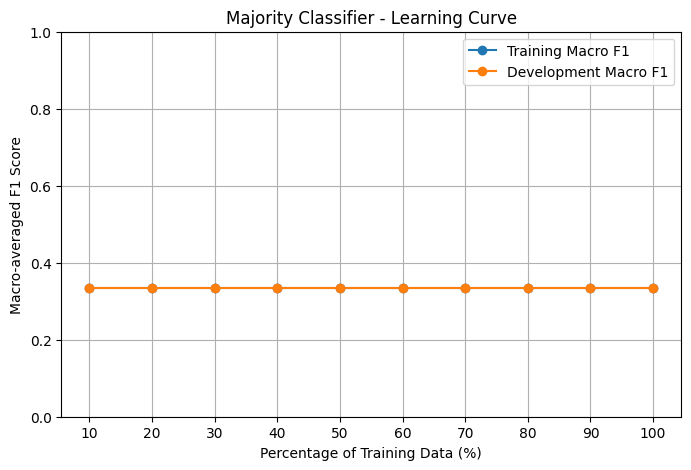

{'Majority Classifier': {'train': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'dev': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333]}, 'Logistic Regression': {'train': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'dev': [0.7566423308997566, 0.8099472075576549, 0.8466598515489577, 0.8499182888461496, 0.8599439775910365, 0.8599937775012223, 0.8666133119914632, 0.8699869986998701, 0.8633196652998634, 0.8833216654998833]}}


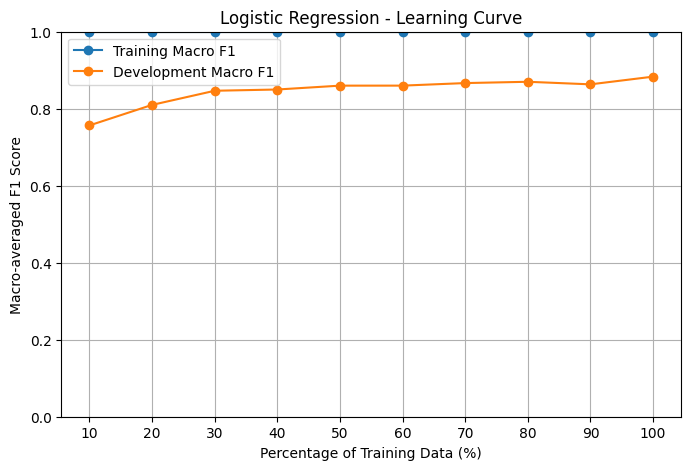

{'Majority Classifier': {'train': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'dev': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333]}, 'Logistic Regression': {'train': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'dev': [0.7566423308997566, 0.8099472075576549, 0.8466598515489577, 0.8499182888461496, 0.8599439775910365, 0.8599937775012223, 0.8666133119914632, 0.8699869986998701, 0.8633196652998634, 0.8833216654998833]}}


In [14]:

# STEP 14: TWO LEARNING CURVES

for classifier_name in classifiers.keys():

    plt.figure(figsize=(8, 5))

    plt.plot(
        percentages,
        learning_results[classifier_name]['train'],
        marker='o',
        label='Training Macro F1'
    )

    plt.plot(
        percentages,
        learning_results[classifier_name]['dev'],
        marker='o',
        label='Development Macro F1'
    )

    plt.title(classifier_name + ' - Learning Curve')

    plt.xlabel('Percentage of Training Data (%)')

    plt.ylabel('Macro-averaged F1 Score')

    plt.ylim(0, 1)

    plt.xticks(percentages)

    plt.grid(True)

    plt.legend()

    plt.show()
    print(learning_results)

